In [47]:
%matplotlib inline
from google.cloud import bigquery
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from langchain_core.prompts import ChatPromptTemplate
from langchain_google_genai import ChatGoogleGenerativeAI
import os
from IPython.display import display,Markdown
import torch
from transformers import pipeline
from lingua import LanguageDetectorBuilder,Language

# **SUMMARY**
Exploratory analysis of one week of data from the public Google Trends dataset (hourly) in BigQuery, focusing on three U.S. states: California, Florida, and New York (covering 31 DMAs in total). The objective was to identify the most-searched terms, categorize them by topic, and compare search behavior across the states.*

Technical stack: BigQuery, Python, pandas, matplotlib, Hugging Face Transformers (zero-shot classification using MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli), lingua.

# AI MODEL CONFIGURATION

In [2]:
api_key=os.environ.get('GOOGLE_API_KEY')
llm=ChatGoogleGenerativeAI(model='gemini-2.5-flash',temperature=0.4)

# HUGGING FACE MODEL CONFIGURATION

In [3]:
print("¿CUDA disponible?:", torch.cuda.is_available())
print("Dispositivo actual:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Ninguno")

¿CUDA disponible?: True
Dispositivo actual: NVIDIA GeForce RTX 3050 Laptop GPU


In [4]:
device = 0 if torch.cuda.is_available() else -1
print(f"Corriendo en: {'cuda' if device == 0 else 'cpu'}")

base_model = "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli"

classifier = pipeline(
    "zero-shot-classification",
    model=base_model,
    device=device
)

Corriendo en: cuda


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

# BIGQUERY CONNECTION

In [91]:
#PUT YOUR PROJECT ID
client = bigquery.Client(project='')

In [92]:
#Probe
query = """
    SELECT 'Connection success' AS estado
"""
probe = client.query(query).to_dataframe()
print(probe)

               estado
0  Connection success


In [5]:
query = """SELECT * FROM `bigquery-public-data.google_trends_hourly.top_rising_terms_hourly` 
WHERE (refresh_time BETWEEN '2026-09-13T12:00:00' AND '2026-09-19T23:59:59') AND 
(dma_name LIKE '%CA' OR dma_name LIKE '%NY' OR dma_name LIKE '%FL');"""
df=client.query(query).to_dataframe()
df

,rank,percent_gain,refresh_time,dma_name,dma_id,term,week,score
0,24,160,2026-09-18 00:00:00,Buffalo NY,514,bills,2025-09-14,91
1,24,160,2026-09-18 00:00:00,Buffalo NY,514,bills,2025-09-21,27
2,24,160,2026-09-18 00:00:00,Buffalo NY,514,bills,2025-09-28,60
3,24,160,2026-09-18 00:00:00,Buffalo NY,514,bills,2025-10-05,63
4,24,160,2026-09-18 00:00:00,Buffalo NY,514,bills,2025-10-12,59
...,...,...,...,...,...,...,...,...
1010440,9,650,2026-09-17 18:00:00,Monterey-Salinas CA,828,wayground,2026-08-02,<NA>
1010441,9,650,2026-09-17 18:00:00,Monterey-Salinas CA,828,wayground,2026-08-09,86
1010442,9,650,2026-09-17 18:00:00,Monterey-Salinas CA,828,wayground,2026-08-16,86
1010443,9,650,2026-09-17 18:00:00,Monterey-Salinas CA,828,wayground,2026-08-30,26


In [5]:
#AFTER MAKE THE QUERY YOU CAN DOWNLOAD THE DATASET IN YOUR PC
df=pd.read_csv("C:/Users/EfrenMariscal/Downloads/google_terms.csv")

In [6]:
df['refresh_time']=pd.to_datetime(df['refresh_time'],format="ISO8601")
df['week']=pd.to_datetime(df['week'],format="ISO8601")

In [7]:
df.describe()

,rank,percent_gain,refresh_time,dma_id,week,score
count,1.010445e+06,1.010445e+06,1010445,1.010445e+06,1010445,246973.000000
mean,1.250244e+01,1.179008e+03,2026-09-16 15:45:21.951218688,6.584194e+02,2026-03-15 00:00:00.000000512,48.308269
min,1.000000e+00,1.200000e+02,2026-09-13 12:00:00,5.010000e+02,2025-09-14 00:00:00,1.000000
25%,6.000000e+00,4.500000e+02,2026-09-15 00:00:00,5.340000e+02,2025-12-14 00:00:00,25.000000
50%,1.200000e+01,7.000000e+02,2026-09-16 18:00:00,5.710000e+02,2026-03-15 00:00:00,49.000000
75%,1.800000e+01,1.350000e+03,2026-09-18 06:00:00,8.040000e+02,2026-06-14 00:00:00,68.000000
max,2.500000e+01,1.355000e+04,2026-09-19 18:00:00,8.680000e+02,2026-09-13 00:00:00,100.000000
std,7.068972e+00,1.347712e+03,NaN,1.379841e+02,NaN,27.882582


In [8]:
df.isnull().sum()

rank                 0
percent_gain         0
refresh_time         0
dma_name             0
dma_id               0
term                 0
week                 0
score           763472
dtype: int64

# USING AI TO ANALYZE THE COLUMNS OF THE DATASET

In [14]:
df_sample=df.sample(n=20)
df_sample=df_sample.to_dict(orient='records')
template=ChatPromptTemplate.from_messages([
    ('system',"""You are an expert data scientist who analyzes charts and data frames professionally and analytically. You are concise in your answers and provide recommendations and your professional perspective."""),
    ('user',"""Explain the dataset to me clearly and also tell me what mean all the columns. The dataset is: {dataset}""")
])
chain=template|llm
response=chain.invoke({'dataset':df_sample})
display(Markdown(response.content))

This dataset provides insights into trending search terms within specific geographic markets (Designated Market Areas, or DMAs) over time. Each record represents a snapshot of a particular search term's performance in a given DMA during a specific week.

Here's a breakdown of each column:

*   **`refresh_time`**: A timestamp indicating when this particular data record was last updated or refreshed.
*   **`dma_name`**: The name of the Designated Market Area (DMA), which is a geographic region in the United States used by Nielsen for local television market measurement.
*   **`dma_id`**: A unique numerical identifier for the Designated Market Area.
*   **`term`**: The specific search query or keyword that is being tracked for its trendiness.
*   **`week`**: The start date of the week to which the associated `score`, `rank`, and `percent_gain` metrics apply for the given `term` and `dma`.
*   **`score`**: A numerical value representing the search interest or popularity of the `term` within the `dma` for that `week`. A higher score indicates greater interest. `None` suggests no specific score was recorded or available for that entry.
*   **`rank`**: The ranking of the `term` among other trending terms within that `dma` for that `week`. A lower number (e.g., 1) indicates a higher position or greater trendiness.
*   **`percent_gain`**: The percentage increase in search interest for the `term` within the `dma` for that `week`, typically compared to a previous period (e.g., the prior week or a baseline average). This highlights how rapidly a term is gaining popularity.

---

**Professional Perspective & Recommendations:**

This dataset is valuable for understanding localized search trends and identifying emerging topics of interest.

1.  **Trend Analysis:** Leverage `week`, `term`, `dma_name`, `rank`, and `percent_gain` to identify rapidly growing or sustained popular search terms in specific regions. This is crucial for content creation, marketing campaigns, and local news coverage.
2.  **Geographic Segmentation:** Analyze differences in search trends across various DMAs to understand regional interests and cultural nuances.
3.  **Missing Data Handling:** The `score` column frequently contains `None` values. Before performing any quantitative analysis on `score`, it's essential to understand the reason for these missing values and decide on an appropriate imputation strategy or simply exclude these records if `score` is a primary metric.
4.  **Time Series Potential:** The `week` column allows for time-series analysis to observe seasonality, long-term trends, and the lifecycle of search terms.
5.  **Actionable Insights:** This data can inform media buying decisions, localized SEO strategies, and product development by highlighting what specific audiences are actively searching for.

# EXPLORATORY DATA ANALYSIS (EDA)

In [9]:
df.head(5)

,rank,percent_gain,refresh_time,dma_name,dma_id,term,week,score
0,24,160,2026-09-18,Buffalo NY,514,bills,2025-09-14,91.0
1,24,160,2026-09-18,Buffalo NY,514,bills,2025-09-21,27.0
2,24,160,2026-09-18,Buffalo NY,514,bills,2025-09-28,60.0
3,24,160,2026-09-18,Buffalo NY,514,bills,2025-10-05,63.0
4,24,160,2026-09-18,Buffalo NY,514,bills,2025-10-12,59.0


In [10]:
print(df['term'].value_counts().head(10))
print()
print(df['refresh_time'].dt.day_name().value_counts())

term
hebeos.com          11501
zimbio.com          11501
woodlands inn       11501
tiempo de mañana     9858
weather tomorrow     9858
blooket join         8215
gimkit               8215
wayground            8215
unblocked games      8215
ixl                  8215
Name: count, dtype: int64

refresh_time
Thursday     164300
Friday       161014
Tuesday      161014
Wednesday    156085
Monday       152799
Saturday     149513
Sunday        65720
Name: count, dtype: int64


In [11]:
print(df['refresh_time'].dt.hour.value_counts())
print()
print(df['dma_name'].str.split().str[-1].value_counts())

refresh_time
18    287525
0     246450
6     246450
12    230020
Name: count, dtype: int64

dma_name
CA    391140
NY    325950
FL    293355
Name: count, dtype: int64


### GRAPHS
**terms:** *The terms more searched in the different states were hebeos.com,zimbio.com,woodlands inn,tiempo mañana,etc. There were spanish terms, this mean that the hispanic population is very important.*\
**days:** *The number of searches were similar in various days, but at the end 'Thursday' was the day with more searches followed by 'Friday','Tuesday','Wednesday','Monday','Saturday' and 'Sunday'.*\
**hour:** *The dataset report only 4 hours per day (18,0,6 and 12). 6pm (18) had more searches in general followed by 12am (0), 6am (6) and 12pm (12).*\
**states:** *There were more searches in California followed by New York and Florida.*

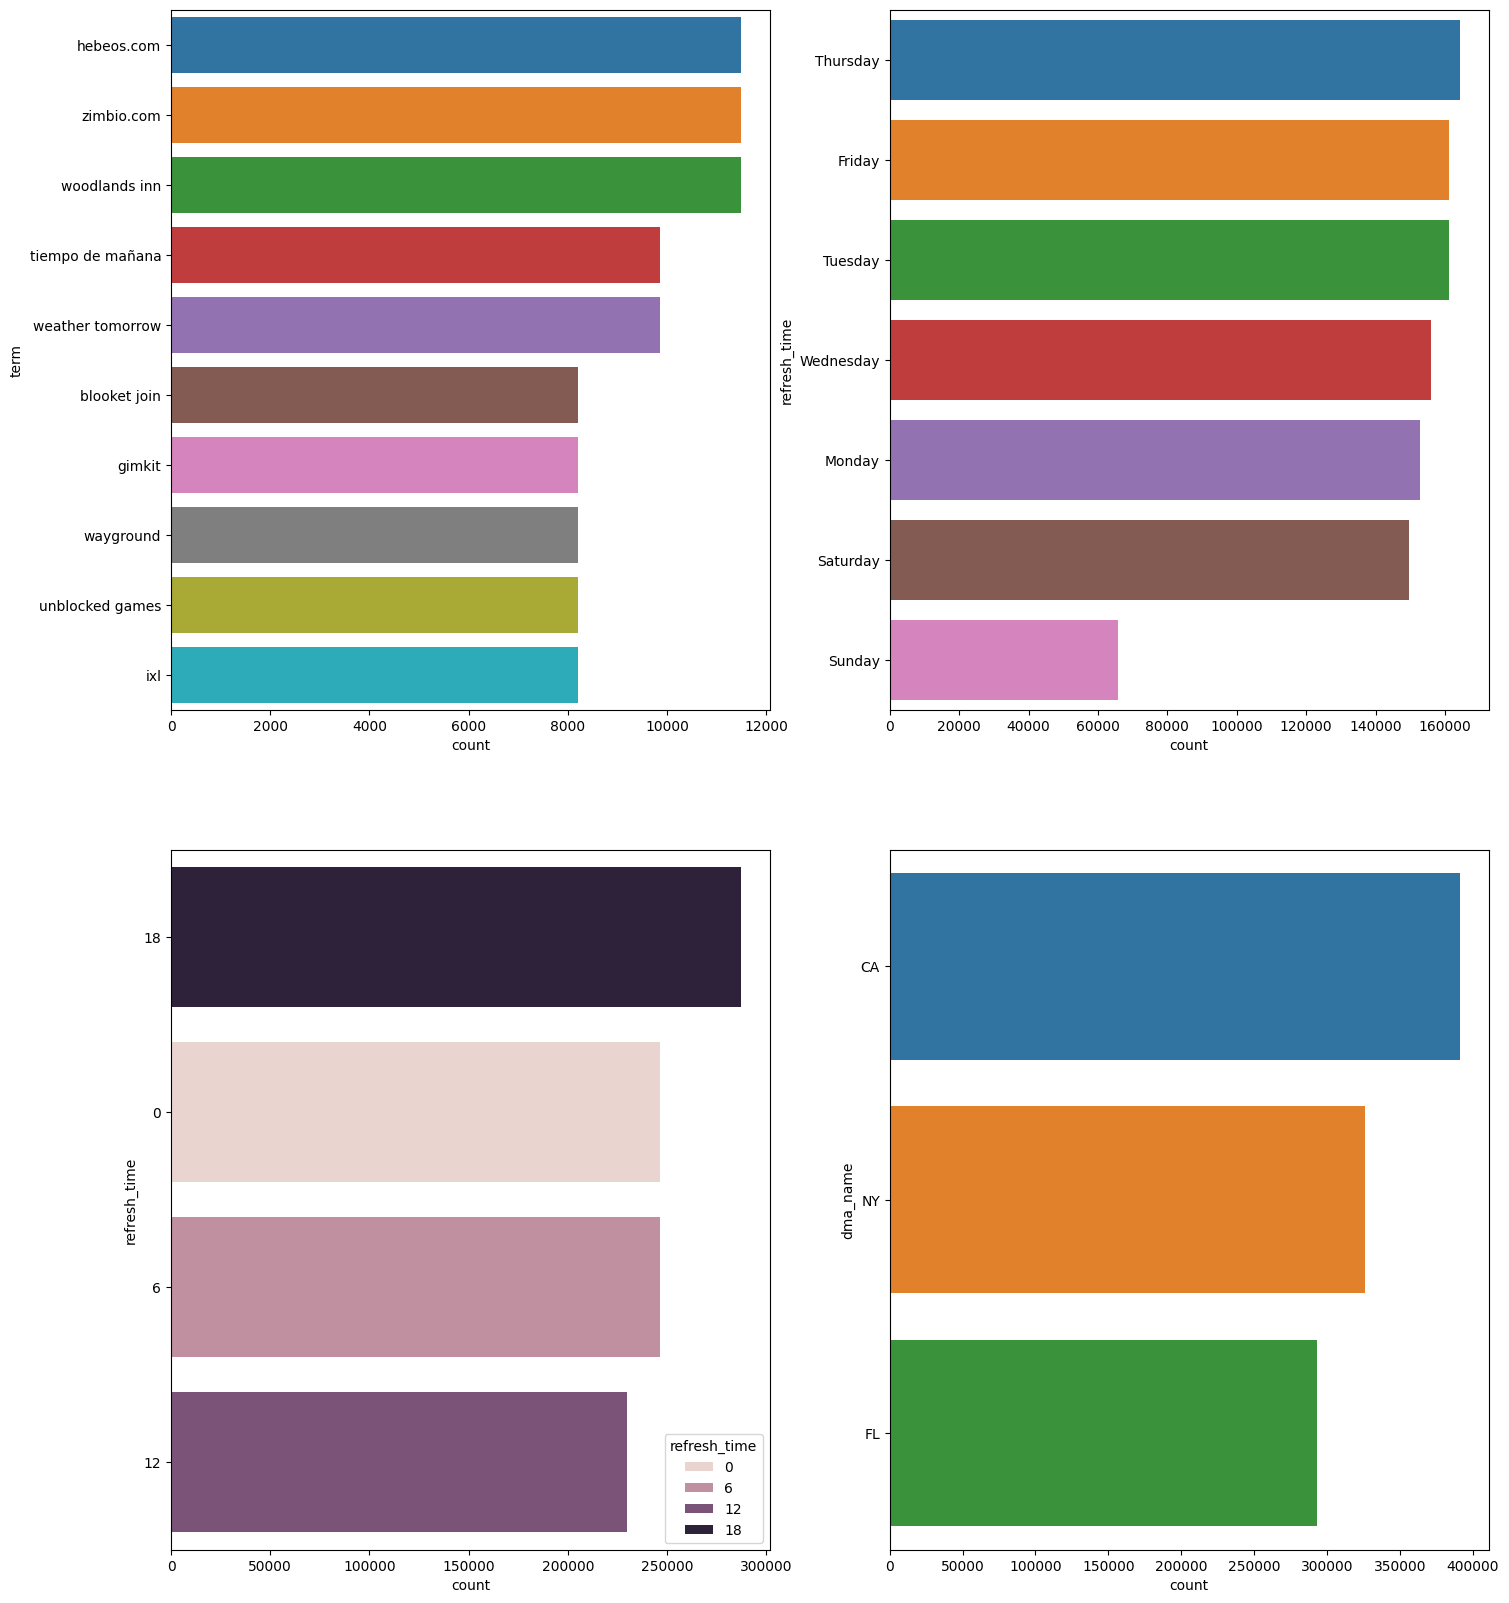

In [12]:
fig,ax=plt.subplots(nrows=2,ncols=2,figsize=(17,20))
ax1=ax[0,0];ax2=ax[0,1];ax3=ax[1,0];ax4=ax[1,1];

words_ten=df['term'].value_counts().head(10).reset_index()
sns.barplot(data=words_ten,y='term',x='count',hue='term',ax=ax1)

days=df['refresh_time'].dt.day_name().value_counts().reset_index()
sns.barplot(data=days,y='refresh_time',x='count',hue='refresh_time',ax=ax2)

hours=df['refresh_time'].dt.hour.value_counts().reset_index()
sns.barplot(data=hours,y=hours['refresh_time'].astype('str'),x='count',hue='refresh_time',ax=ax3)

states=df['dma_name'].str.split().str[-1].value_counts().reset_index()
sns.barplot(data=states,y='dma_name',x='count',hue='dma_name',ax=ax4);

### TERMS WITH MORE RECORDS IN THE DIFFERENT STATES
**Terms in different states:** *There was searched the same terms in the different states, there weren't differences or exclusive terms of the states.
The next terms were searched in descendent order: 'hebeos.com','zimbio.com','woodlands inn','tiempo de mañana','weather tomorrow','blooket join','gimkit','wayground','unblocked games','ixl'. These terms has relationship with the most searched terms in general.*

In [13]:
df['states']=df['dma_name'].apply(lambda x:
                                    'CA' if str(x).endswith('CA') else
                                    'FL' if str(x).endswith('FL') else
                                    'NY' if str(x).endswith('NY') else 0)

In [14]:
#california=df.loc[df['dma_name'].str.split().str[-1]=='CA']
#florida=df.loc[df['dma_name'].str.split().str[-1]=='FL']
#new_york=df.loc[df['dma_name'].str.split().str[-1]=='NY']

california=df.loc[df['states']=='CA']
florida=df.loc[df['states']=='FL']
new_york=df.loc[df['states']=='NY']

In [15]:
print(california['term'].value_counts().head(10))
print()
print(florida['term'].value_counts().head(10))
print()
print(new_york['term'].value_counts().head(10))

term
hebeos.com          4452
zimbio.com          4452
woodlands inn       4452
tiempo de mañana    3816
weather tomorrow    3816
blooket join        3180
gimkit              3180
wayground           3180
unblocked games     3180
ixl                 3180
Name: count, dtype: int64

term
hebeos.com          3339
zimbio.com          3339
woodlands inn       3339
tiempo de mañana    2862
weather tomorrow    2862
blooket join        2385
gimkit              2385
wayground           2385
unblocked games     2385
ixl                 2385
Name: count, dtype: int64

term
hebeos.com          3710
zimbio.com          3710
woodlands inn       3710
tiempo de mañana    3180
weather tomorrow    3180
blooket join        2650
gimkit              2650
wayground           2650
unblocked games     2650
ixl                 2650
Name: count, dtype: int64


In [16]:
ca_ten=california['term'].value_counts().head(10).reset_index()
ca_ten['state']='California'
fl_ten=florida['term'].value_counts().head(10).reset_index()
fl_ten['state']='Florida'
ny_ten=new_york['term'].value_counts().head(10).reset_index()
ny_ten['state']='New York'
top_terms=pd.concat([ca_ten,fl_ten,ny_ten],ignore_index=True)

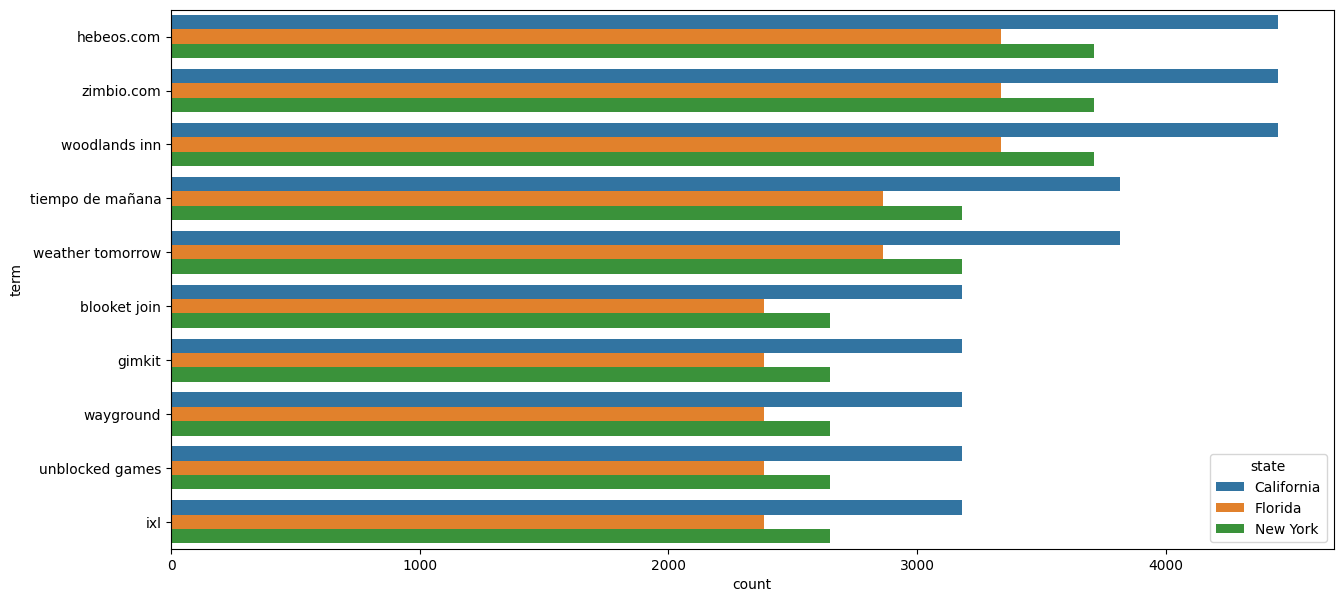

In [17]:
plt.figure(figsize=(15,7))
sns.barplot(data=top_terms,y='term',x='count',hue='state');

### GROWING OF THE TERMS IN THE DIFFERENT STATES OVER THE TIME
**percent gain terms:** *The principal terms were the same in the different states just like the proportion of the percent gain of the terms. 'woodlands inn','hebeos.com' and 'zimbio.com' persisted along the week and increased the percent gain on weekends. On the other hand there were terms that lasted 5 days without percent gain along the week and there were other terms that the percent gain was the same along the week.*

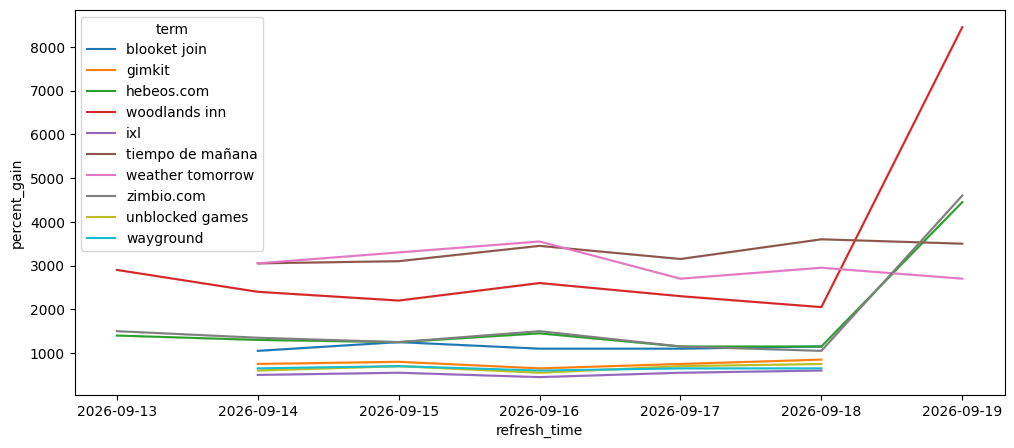

In [18]:
#CALIFORNIA
top_gnral=ca_ten['term'].values
top_gnral=california.loc[california['term'].isin(top_gnral)]
plt.figure(figsize=(12,5))
sns.lineplot(data=top_gnral,y='percent_gain',x=top_gnral['refresh_time'].dt.date,hue='term');

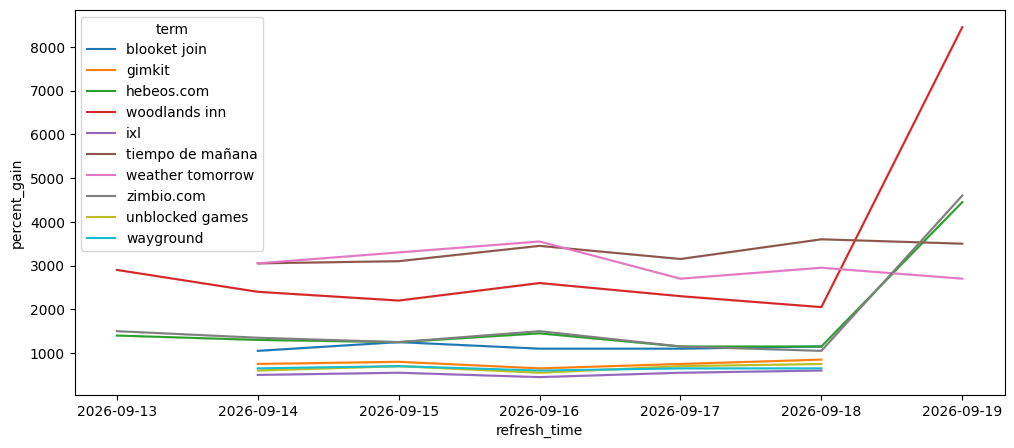

In [19]:
#FLORIDA
top_gnral_fl=fl_ten['term'].values
top_gnral_fl=california.loc[california['term'].isin(top_gnral_fl)]
plt.figure(figsize=(12,5))
sns.lineplot(data=top_gnral_fl,y='percent_gain',x=top_gnral_fl['refresh_time'].dt.date,hue='term');

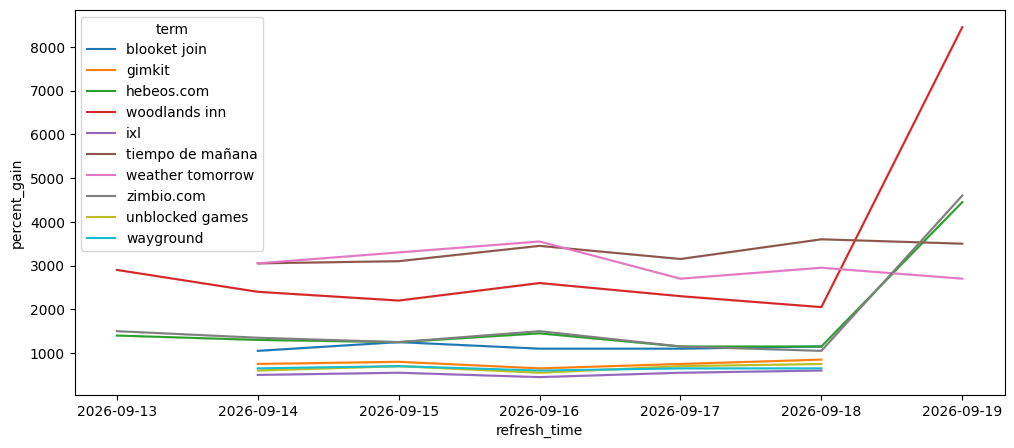

In [20]:
#CALIFORNIA
top_gnral_ny=ny_ten['term'].values
top_gnral_ny=california.loc[california['term'].isin(top_gnral_ny)]
plt.figure(figsize=(12,5))
sns.lineplot(data=top_gnral_ny,y='percent_gain',x=top_gnral_ny['refresh_time'].dt.date,hue='term');

In [21]:

california[['term','rank','percent_gain']].value_counts().reset_index().sort_values(['rank','percent_gain'],ascending=[True,False])

,term,rank,percent_gain,count
258,how do i register to vote,1,13550,636
19,barcelona racing de santander,1,11450,636
178,elche c. f. real madrid,1,10650,636
588,woodlands inn,1,8450,636
336,levante barcelona,1,8200,636
...,...,...,...,...
167,drug store,25,250,636
577,what time is dancing with the stars on,25,200,636
269,indiana fever,25,180,636
201,football games today,25,150,636


### WHAT KIND OF CATEGORY DO THE TERMS BELONG?
#### USING HUGGING FACE MODELS FOR CATEGORIZATION OF THE TERMS
**categories:** *The states sharing the same categories. There were more sport searches followed by person,entertainment,organization,location,technology,business,event,travel and weather. The categories with more percent gain were weather followed by location,business,person,sports,event,organization,entertainment,travel and technology.*

In [22]:
#categories = ["music", "weather", "sports", "politics", "entertainment",'health','business','technology','science','education']
categories = ["person",
    "organization",
    "product",
    "entertainment",
    "sports",
    "politics",
    "business",
    "technology",
    "health",
    "education",
    "travel",
    "weather",
    "event",
    "location",
    "other"]

In [23]:
terms=df['term'].drop_duplicates().to_list()
clasification=classifier(terms,candidate_labels=categories,batch_size=16,truncation=True)

In [24]:
df_categories = pd.DataFrame([
    {
        'term': res['sequence'],
        'category': res['labels'][0],
        'score_cat': res['scores'][0]
    }
    for res in clasification
])
df_categories

,term,category,score_cat
0,bills,business,0.554243
1,bills game,sports,0.654771
2,bills vs lions,politics,0.350765
3,debby ryan brain injury,person,0.654961
4,earthquake now,event,0.774911
...,...,...,...
455,yankees vs twins,sports,0.774995
456,tigers vs white sox,sports,0.328635
457,yankees vs diamondbacks,sports,0.783294
458,ind vs afg,weather,0.360855


In [25]:
#df=df.drop(columns=['category_x','score_cat_x','category_y','score_cat_y','category','score_cat'])

In [26]:
df=df.merge(df_categories,on='term',how='left')
df

,rank,percent_gain,refresh_time,dma_name,dma_id,term,week,score,states,category,score_cat
0,24,160,2026-09-18 00:00:00,Buffalo NY,514,bills,2025-09-14,91.0,NY,business,0.554243
1,24,160,2026-09-18 00:00:00,Buffalo NY,514,bills,2025-09-21,27.0,NY,business,0.554243
2,24,160,2026-09-18 00:00:00,Buffalo NY,514,bills,2025-09-28,60.0,NY,business,0.554243
3,24,160,2026-09-18 00:00:00,Buffalo NY,514,bills,2025-10-05,63.0,NY,business,0.554243
4,24,160,2026-09-18 00:00:00,Buffalo NY,514,bills,2025-10-12,59.0,NY,business,0.554243
...,...,...,...,...,...,...,...,...,...,...,...
1010440,9,650,2026-09-17 18:00:00,Monterey-Salinas CA,828,wayground,2026-08-02,NaN,CA,travel,0.768548
1010441,9,650,2026-09-17 18:00:00,Monterey-Salinas CA,828,wayground,2026-08-09,86.0,CA,travel,0.768548
1010442,9,650,2026-09-17 18:00:00,Monterey-Salinas CA,828,wayground,2026-08-16,86.0,CA,travel,0.768548
1010443,9,650,2026-09-17 18:00:00,Monterey-Salinas CA,828,wayground,2026-08-30,26.0,CA,travel,0.768548


In [27]:
df_california=df[df['states']=='CA'].copy()
df_florida=df[df['states']=='FL'].copy()
df_ny=df[df['states']=='NY'].copy()

In [28]:
print(df_california['category'].value_counts().head(10))
print()
print(df_florida['category'].value_counts().head(10))
print()
print(df_ny['category'].value_counts().head(10))

category
sports           71232
person           49608
entertainment    47700
organization     43884
location         37524
technology       24804
business         23532
event            19716
travel           17172
weather          13992
Name: count, dtype: int64

category
sports           53424
person           37206
entertainment    35775
organization     32913
location         28143
technology       18603
business         17649
event            14787
travel           12879
weather          10494
Name: count, dtype: int64

category
sports           59360
person           41340
entertainment    39750
organization     36570
location         31270
technology       20670
business         19610
event            16430
travel           14310
weather          11660
Name: count, dtype: int64


In [29]:
cal=df_california['category'].value_counts()
flo=df_florida['category'].value_counts()
ny=df_ny['category'].value_counts()
conteos = pd.concat([cal, flo, ny], axis=1, keys=['California', 'Florida', 'Nueva York']).fillna(0).astype(int)
print(conteos)

               California  Florida  Nueva York
category                                      
sports              71232    53424       59360
person              49608    37206       41340
entertainment       47700    35775       39750
organization        43884    32913       36570
location            37524    28143       31270
technology          24804    18603       20670
business            23532    17649       19610
event               19716    14787       16430
travel              17172    12879       14310
weather             13992    10494       11660
politics            12084     9063       10070
product             12084     9063       10070
other                6996     5247        5830
education            5724     4293        4770
health               5088     3816        4240


In [30]:
porcentajes = ((conteos / conteos.sum()) * 100).round(1)
print(porcentajes)

               California  Florida  Nueva York
category                                      
sports               18.2     18.2        18.2
person               12.7     12.7        12.7
entertainment        12.2     12.2        12.2
organization         11.2     11.2        11.2
location              9.6      9.6         9.6
technology            6.3      6.3         6.3
business              6.0      6.0         6.0
event                 5.0      5.0         5.0
travel                4.4      4.4         4.4
weather               3.6      3.6         3.6
politics              3.1      3.1         3.1
product               3.1      3.1         3.1
other                 1.8      1.8         1.8
education             1.5      1.5         1.5
health                1.3      1.3         1.3


In [31]:
diferencias = pd.DataFrame({
    'CA - FL': porcentajes['California'] - porcentajes['Florida'],
    'CA - NY': porcentajes['California'] - porcentajes['Nueva York'],
    'FL - NY': porcentajes['Florida'] - porcentajes['Nueva York'],
}).round(1)
print(diferencias)

               CA - FL  CA - NY  FL - NY
category                                
sports             0.0      0.0      0.0
person             0.0      0.0      0.0
entertainment      0.0      0.0      0.0
organization       0.0      0.0      0.0
location           0.0      0.0      0.0
technology         0.0      0.0      0.0
business           0.0      0.0      0.0
event              0.0      0.0      0.0
travel             0.0      0.0      0.0
weather            0.0      0.0      0.0
politics           0.0      0.0      0.0
product            0.0      0.0      0.0
other              0.0      0.0      0.0
education          0.0      0.0      0.0
health             0.0      0.0      0.0


In [32]:
ca_cat_val=df_california['category'].value_counts().head(10)
fl_cat_val=df_florida['category'].value_counts().head(10)
ny_cat_val=df_ny['category'].value_counts().head(10)
ca_cat=df_california.loc[df_california['category'].isin(ca_cat_val.index)].copy()
fl_cat=df_florida.loc[df_florida['category'].isin(fl_cat_val.index)].copy()
ny_cat=df_ny.loc[df_ny['category'].isin(ny_cat_val.index)].copy()

In [33]:
ca_cat.groupby('category')['percent_gain'].mean().sort_values(ascending=False)

category
weather          1918.181818
location         1634.745763
business         1355.675676
person           1233.974359
sports           1210.089286
event            1196.774194
organization     1190.579710
entertainment     779.600000
travel            709.259259
technology        708.974359
Name: percent_gain, dtype: float64

In [34]:
ca_cat_val=ca_cat_val.reset_index()
ca_cat_val['state']='CA'
fl_cat_val=fl_cat_val.reset_index()
fl_cat_val['state']='FL'
ny_cat_val=ny_cat_val.reset_index()
ny_cat_val['state']='NY'
top_cat=pd.concat([ca_cat_val,fl_cat_val,ny_cat_val],ignore_index=True)

In [35]:
top_cat

,category,count,state
0,sports,71232,CA
1,person,49608,CA
2,entertainment,47700,CA
3,organization,43884,CA
4,location,37524,CA
5,technology,24804,CA
6,business,23532,CA
7,event,19716,CA
8,travel,17172,CA
9,weather,13992,CA


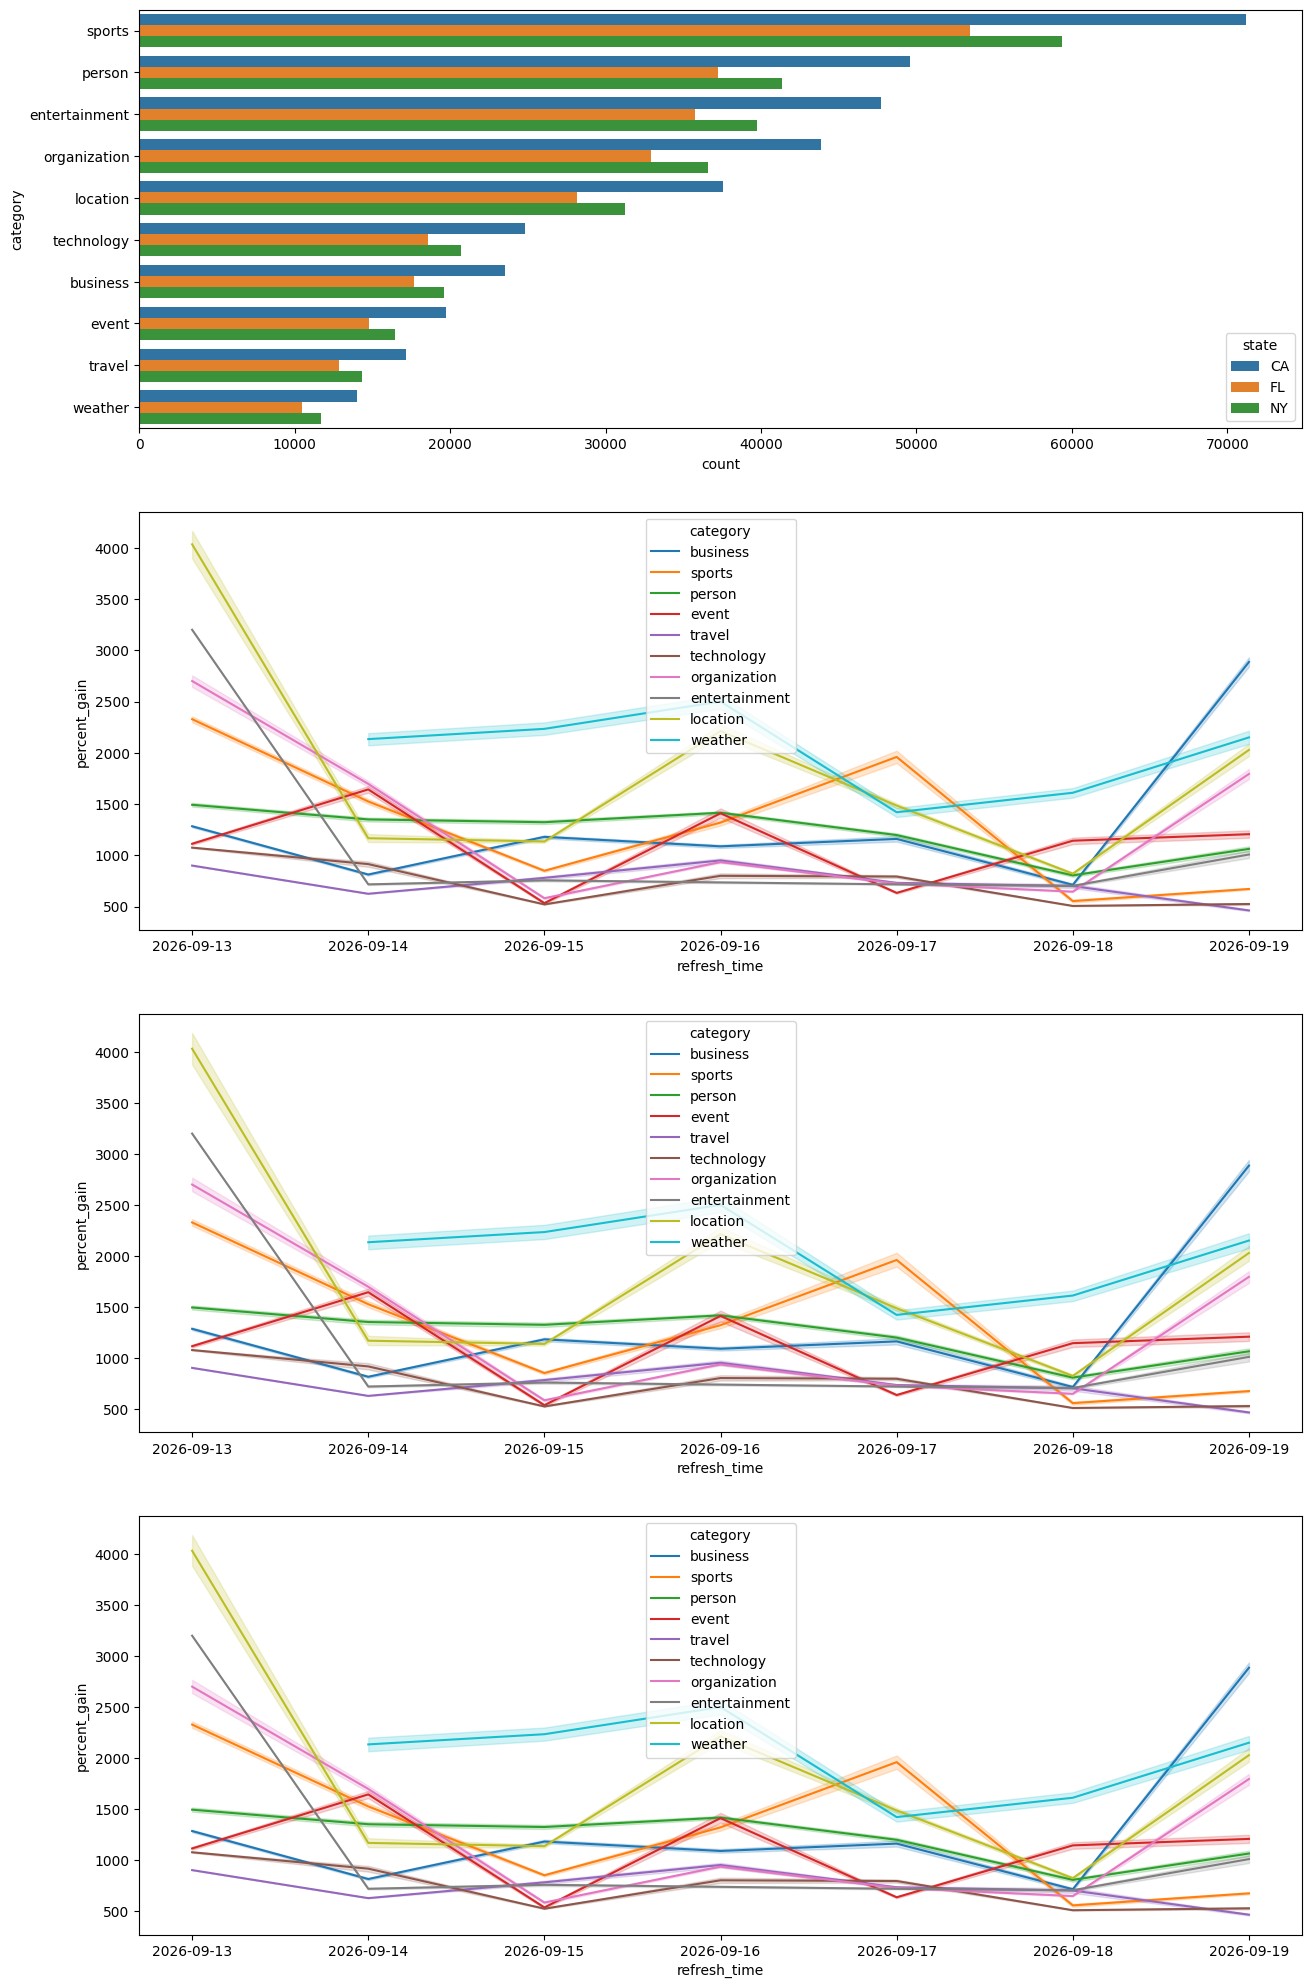

In [63]:
fig,ax=plt.subplots(nrows=4,ncols=1,figsize=(15,25))
ax1=ax[0];ax2=ax[1];ax3=ax[2];ax4=ax[3];

sns.barplot(data=top_cat,y='category',x='count',hue='state',ax=ax1)
sns.lineplot(data=ca_cat,y='percent_gain',x=ca_cat['refresh_time'].dt.date,hue='category',ax=ax2)
sns.lineplot(data=fl_cat,y='percent_gain',x=fl_cat['refresh_time'].dt.date,hue='category',ax=ax3)
sns.lineplot(data=ny_cat,y='percent_gain',x=ny_cat['refresh_time'].dt.date,hue='category',ax=ax4);

### WHAT PROPORTION IS IN ENGLISH AND SPANISH? 
**language of the terms:** *There were more terms in english searched as expected but spanish terms had a significant number, this mean that hispanic population have influence.*

In [48]:
detector = LanguageDetectorBuilder.from_languages(
    Language.ENGLISH,
    Language.SPANISH
).build()

In [49]:
df.head(5)

,rank,percent_gain,refresh_time,dma_name,dma_id,term,week,score,states,category,score_cat
0,24,160,2026-09-18,Buffalo NY,514,bills,2025-09-14,91.0,NY,business,0.554243
1,24,160,2026-09-18,Buffalo NY,514,bills,2025-09-21,27.0,NY,business,0.554243
2,24,160,2026-09-18,Buffalo NY,514,bills,2025-09-28,60.0,NY,business,0.554243
3,24,160,2026-09-18,Buffalo NY,514,bills,2025-10-05,63.0,NY,business,0.554243
4,24,160,2026-09-18,Buffalo NY,514,bills,2025-10-12,59.0,NY,business,0.554243


In [50]:
def detectar_idioma(termino):
    if pd.isna(termino) or not str(termino).strip():
        return "Desconocido"

    resultado = detector.detect_language_of(str(termino))

    if resultado is None:
        return "Desconocido"

    return resultado.name

df["language"] = df["term"].apply(detectar_idioma)

df[["term", "language"]].head(5)

,term,language
0,bills,ENGLISH
1,bills,ENGLISH
2,bills,ENGLISH
3,bills,ENGLISH
4,bills,ENGLISH


In [61]:
df_lang=df['language'].value_counts().reset_index()
df_lang['percentage']=round(df_lang['count']/df_lang['count'].sum(),3)
df_lang

,language,count,percentage
0,ENGLISH,819857,0.811
1,SPANISH,188945,0.187
2,Desconocido,1643,0.002


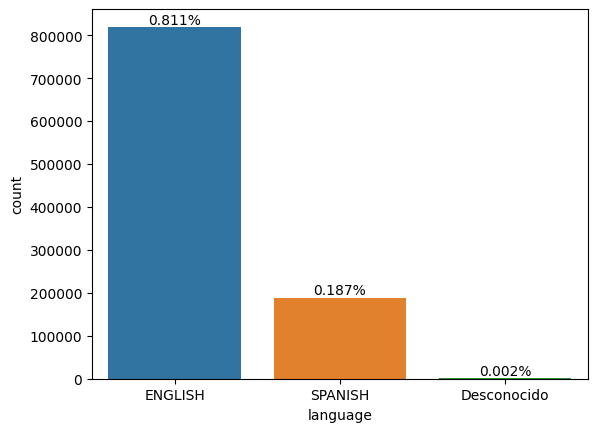

In [62]:
ax = sns.barplot(data=df_lang,x='language',y='count',hue='language')
for i, row in df_lang.reset_index(drop=True).iterrows():
    ax.text(
        i,
        row['count'],
        f"{row['percentage']}%",
        ha='center',
        va='bottom'
    )
plt.show()

In [81]:
#LANGUAGES OF THE DIFFERENT STATES
df.groupby(['states','language']).size()

states  language   
CA      Desconocido       636
        ENGLISH        317364
        SPANISH         73140
FL      Desconocido       477
        ENGLISH        238023
        SPANISH         54855
NY      Desconocido       530
        ENGLISH        264470
        SPANISH         60950
dtype: int64

### WHICH TERMS SAW THE GREATEST GROWTH AND IN WHICH STATE?
**growth of the terms:** *The different states sharing the same terms and growth.*

In [38]:
california[['term','percent_gain']].value_counts().reset_index().sort_values('percent_gain',ascending=False).head(5)

,term,percent_gain,count
250,how do i register to vote,13550,636
30,barcelona racing de santander,11450,636
176,elche c. f. real madrid,10650,636
569,woodlands inn,8450,636
33,barcelona vs racing santander,8350,636


In [101]:
fastest_california = (
    california.groupby(['dma_name', 'term'])['percent_gain']
    .mean()
    .reset_index()
    .sort_values(by=['dma_name', 'percent_gain'], ascending=[True, False])
)


fastest_california['percentage %']=(fastest_california['percent_gain']/fastest_california['percent_gain'].sum())*100
fastest_california.head(5)

,dma_name,term,percent_gain,percentage %
17,Bakersfield CA,barcelona racing de santander,11450.0,0.175437
136,Bakersfield CA,elche c. f. real madrid,10650.0,0.163179
19,Bakersfield CA,barcelona vs racing santander,8350.0,0.127939
254,Bakersfield CA,levante barcelona,8200.0,0.125640
194,Bakersfield CA,how do i register to vote,6975.0,0.106871


In [102]:
fastest_florida = (
    florida.groupby(['dma_name', 'term'])['percent_gain']
    .mean()
    .reset_index()
    .sort_values(by=['dma_name', 'percent_gain'], ascending=[True, False])
)


fastest_florida['percentage']=(fastest_florida['percent_gain']/fastest_florida['percent_gain'].sum())*100
fastest_florida.head(5)

,dma_name,term,percent_gain,percentage
17,Ft. Myers-Naples FL,barcelona racing de santander,11450.0,0.233916
136,Ft. Myers-Naples FL,elche c. f. real madrid,10650.0,0.217572
19,Ft. Myers-Naples FL,barcelona vs racing santander,8350.0,0.170585
254,Ft. Myers-Naples FL,levante barcelona,8200.0,0.167520
194,Ft. Myers-Naples FL,how do i register to vote,6975.0,0.142494


In [41]:
fastest_new_york = (
    new_york.groupby(['dma_name', 'term'])['percent_gain']
    .mean()
    .reset_index()
    .sort_values(by=['dma_name', 'percent_gain'], ascending=[True, False])
)

fastest_new_york['percentage']=(fastest_new_york['percent_gain']/fastest_new_york['percent_gain'].sum())*100
fastest_new_york.head(5)

,dma_name,term,percent_gain,percentage
17,Albany-Schenectady-Troy NY,barcelona racing de santander,11450.0,0.210524
136,Albany-Schenectady-Troy NY,elche c. f. real madrid,10650.0,0.195815
19,Albany-Schenectady-Troy NY,barcelona vs racing santander,8350.0,0.153526
254,Albany-Schenectady-Troy NY,levante barcelona,8200.0,0.150768
194,Albany-Schenectady-Troy NY,how do i register to vote,6975.0,0.128245


In [42]:
terms_five=fastest_california['term'].head(5).values
california_five=california.loc[california['term'].isin(terms_five)]
florida_five=florida.loc[florida['term'].isin(terms_five)]
newyork_five=new_york.loc[new_york['term'].isin(terms_five)]

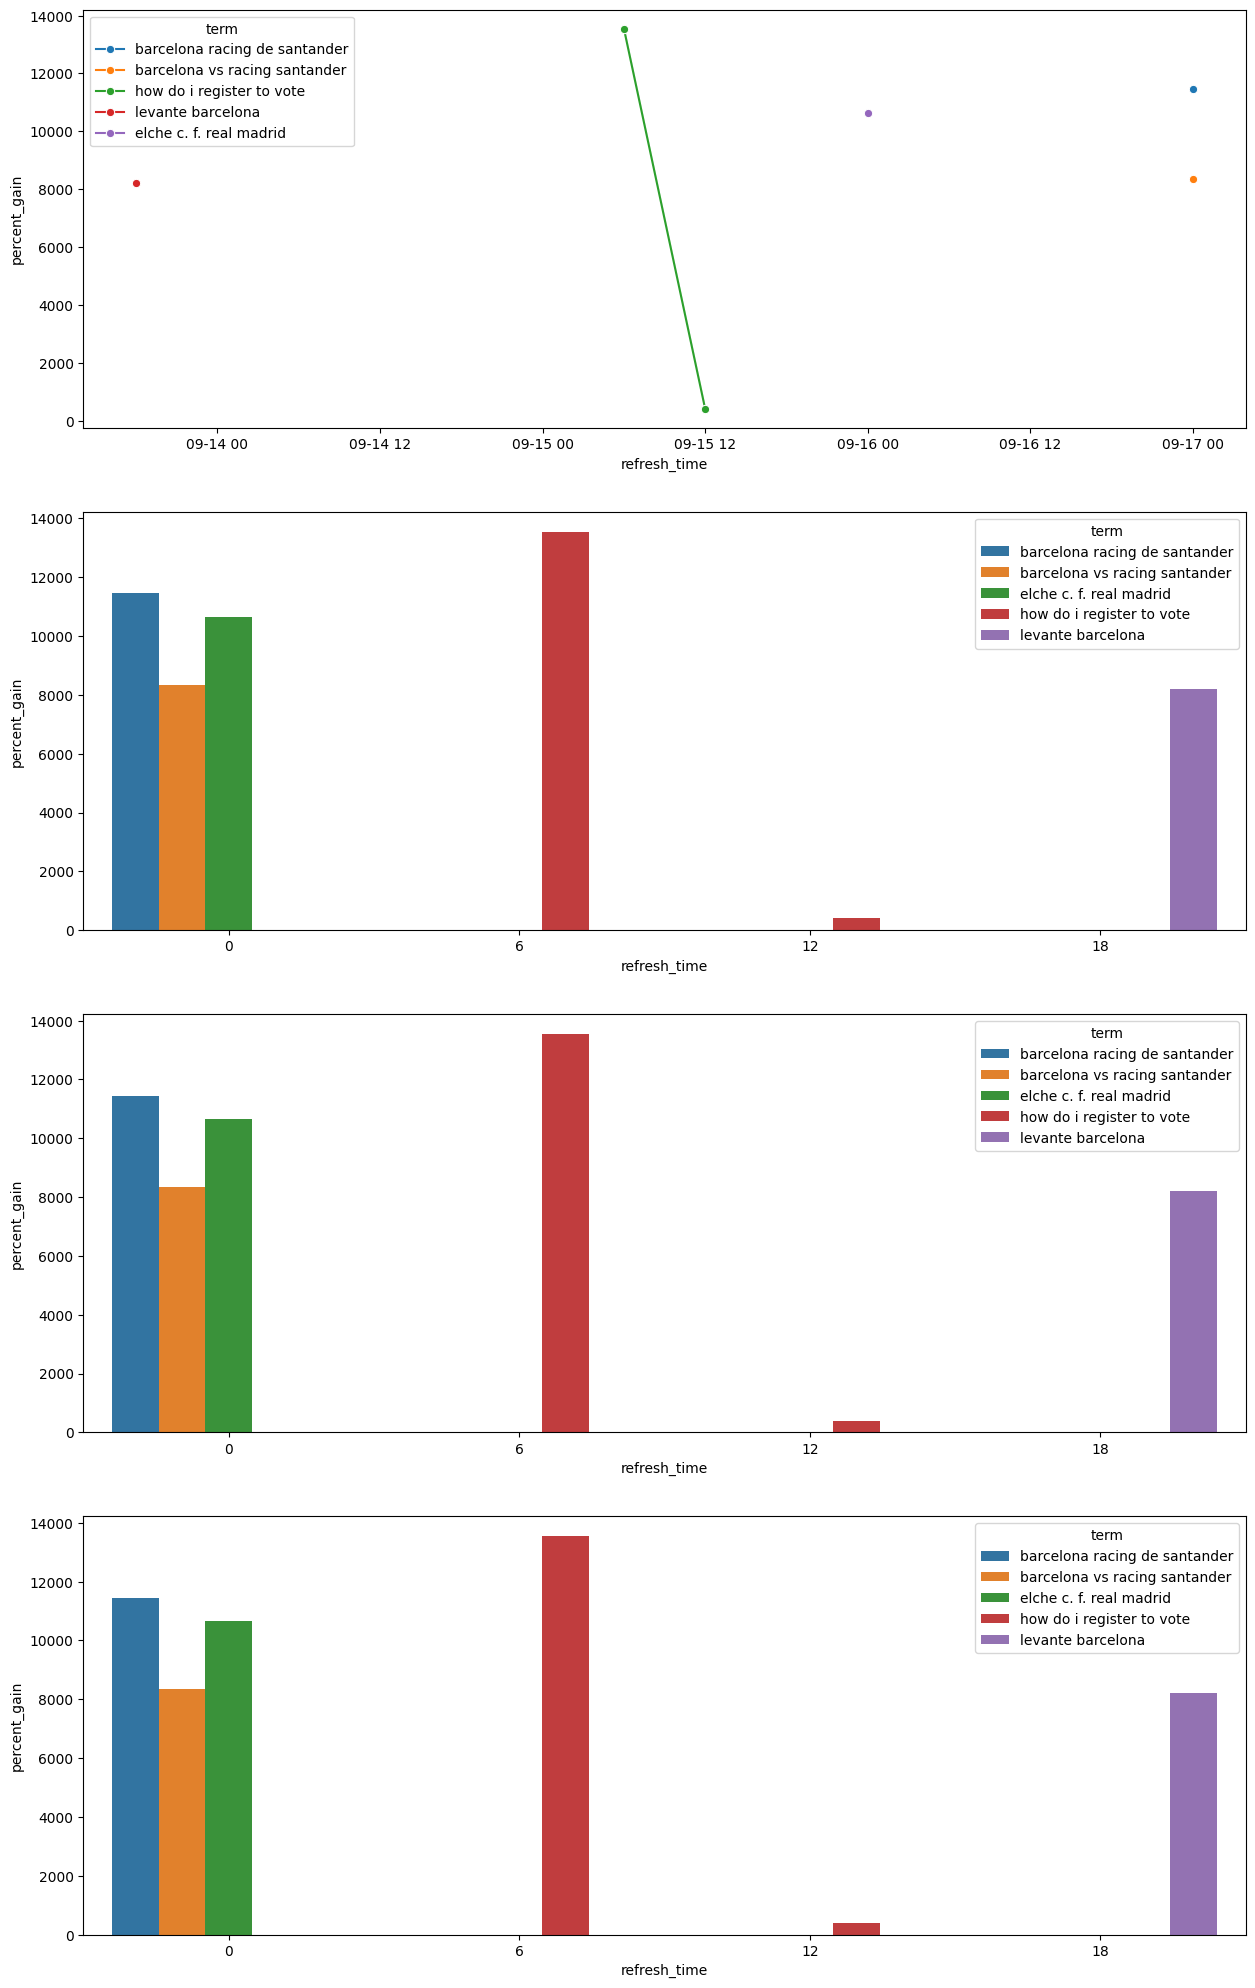

In [43]:
fig,ax=plt.subplots(nrows=4,ncols=1,figsize=(15,25))
ax1=ax[0];ax2=ax[1];ax3=ax[2];ax4=ax[3];
sns.lineplot(data=california_five,y='percent_gain',x='refresh_time',hue='term',marker='o',ax=ax1)
sns.barplot(data=california_five,y='percent_gain',x=california_five['refresh_time'].dt.hour,hue='term',ax=ax2)
sns.barplot(data=florida_five,y='percent_gain',x=florida_five['refresh_time'].dt.hour,hue='term',ax=ax3)
sns.barplot(data=newyork_five,y='percent_gain',x=newyork_five['refresh_time'].dt.hour,hue='term',ax=ax4);

### WHAT WERE THE SPECIFIC TERMS FOR EACH OF THE FASTEST-GROWING STATES?
**growth of terms exclusive to each state:** *There weren't exclusive terms.*

In [64]:
df.head(5)

,rank,percent_gain,refresh_time,dma_name,dma_id,term,week,score,states,category,score_cat,language
0,24,160,2026-09-18,Buffalo NY,514,bills,2025-09-14,91.0,NY,business,0.554243,ENGLISH
1,24,160,2026-09-18,Buffalo NY,514,bills,2025-09-21,27.0,NY,business,0.554243,ENGLISH
2,24,160,2026-09-18,Buffalo NY,514,bills,2025-09-28,60.0,NY,business,0.554243,ENGLISH
3,24,160,2026-09-18,Buffalo NY,514,bills,2025-10-05,63.0,NY,business,0.554243,ENGLISH
4,24,160,2026-09-18,Buffalo NY,514,bills,2025-10-12,59.0,NY,business,0.554243,ENGLISH


In [73]:
#SEARCHING EXCLUSIVE TERMS PER STATE
states_terms = df.groupby('term')['states'].nunique()
unique_terms = states_terms[states_terms == 1].index

In [76]:
unique_terms

Index([], dtype='object', name='term')

In [77]:
states_terms

term
aaron judge                   3
abrahamquirosvillalba .com    3
afg vs ind                    3
al ain vs al-nassr            3
alavés gloriosas barcelona    3
                             ..
zay flowers                   3
zimbio                        3
zimbio.com                    3
zverev                        3
如何 进行 投票 登记                   3
Name: states, Length: 460, dtype: int64

### CATEGORIES WITH MORE GROWING IN EACH STATE

In [89]:
print(df_california.groupby('category')['percent_gain'].mean().sort_values(ascending=False).head(5))
print()
print(df_florida.groupby('category')['percent_gain'].mean().sort_values(ascending=False).head(5))
print()
print(df_ny.groupby('category')['percent_gain'].mean().sort_values(ascending=False).head(5))

category
health      2000.000000
weather     1918.181818
location    1634.745763
politics    1484.210526
business    1355.675676
Name: percent_gain, dtype: float64

category
health      2000.000000
weather     1918.181818
location    1634.745763
politics    1484.210526
business    1355.675676
Name: percent_gain, dtype: float64

category
health      2000.000000
weather     1918.181818
location    1634.745763
politics    1484.210526
business    1355.675676
Name: percent_gain, dtype: float64


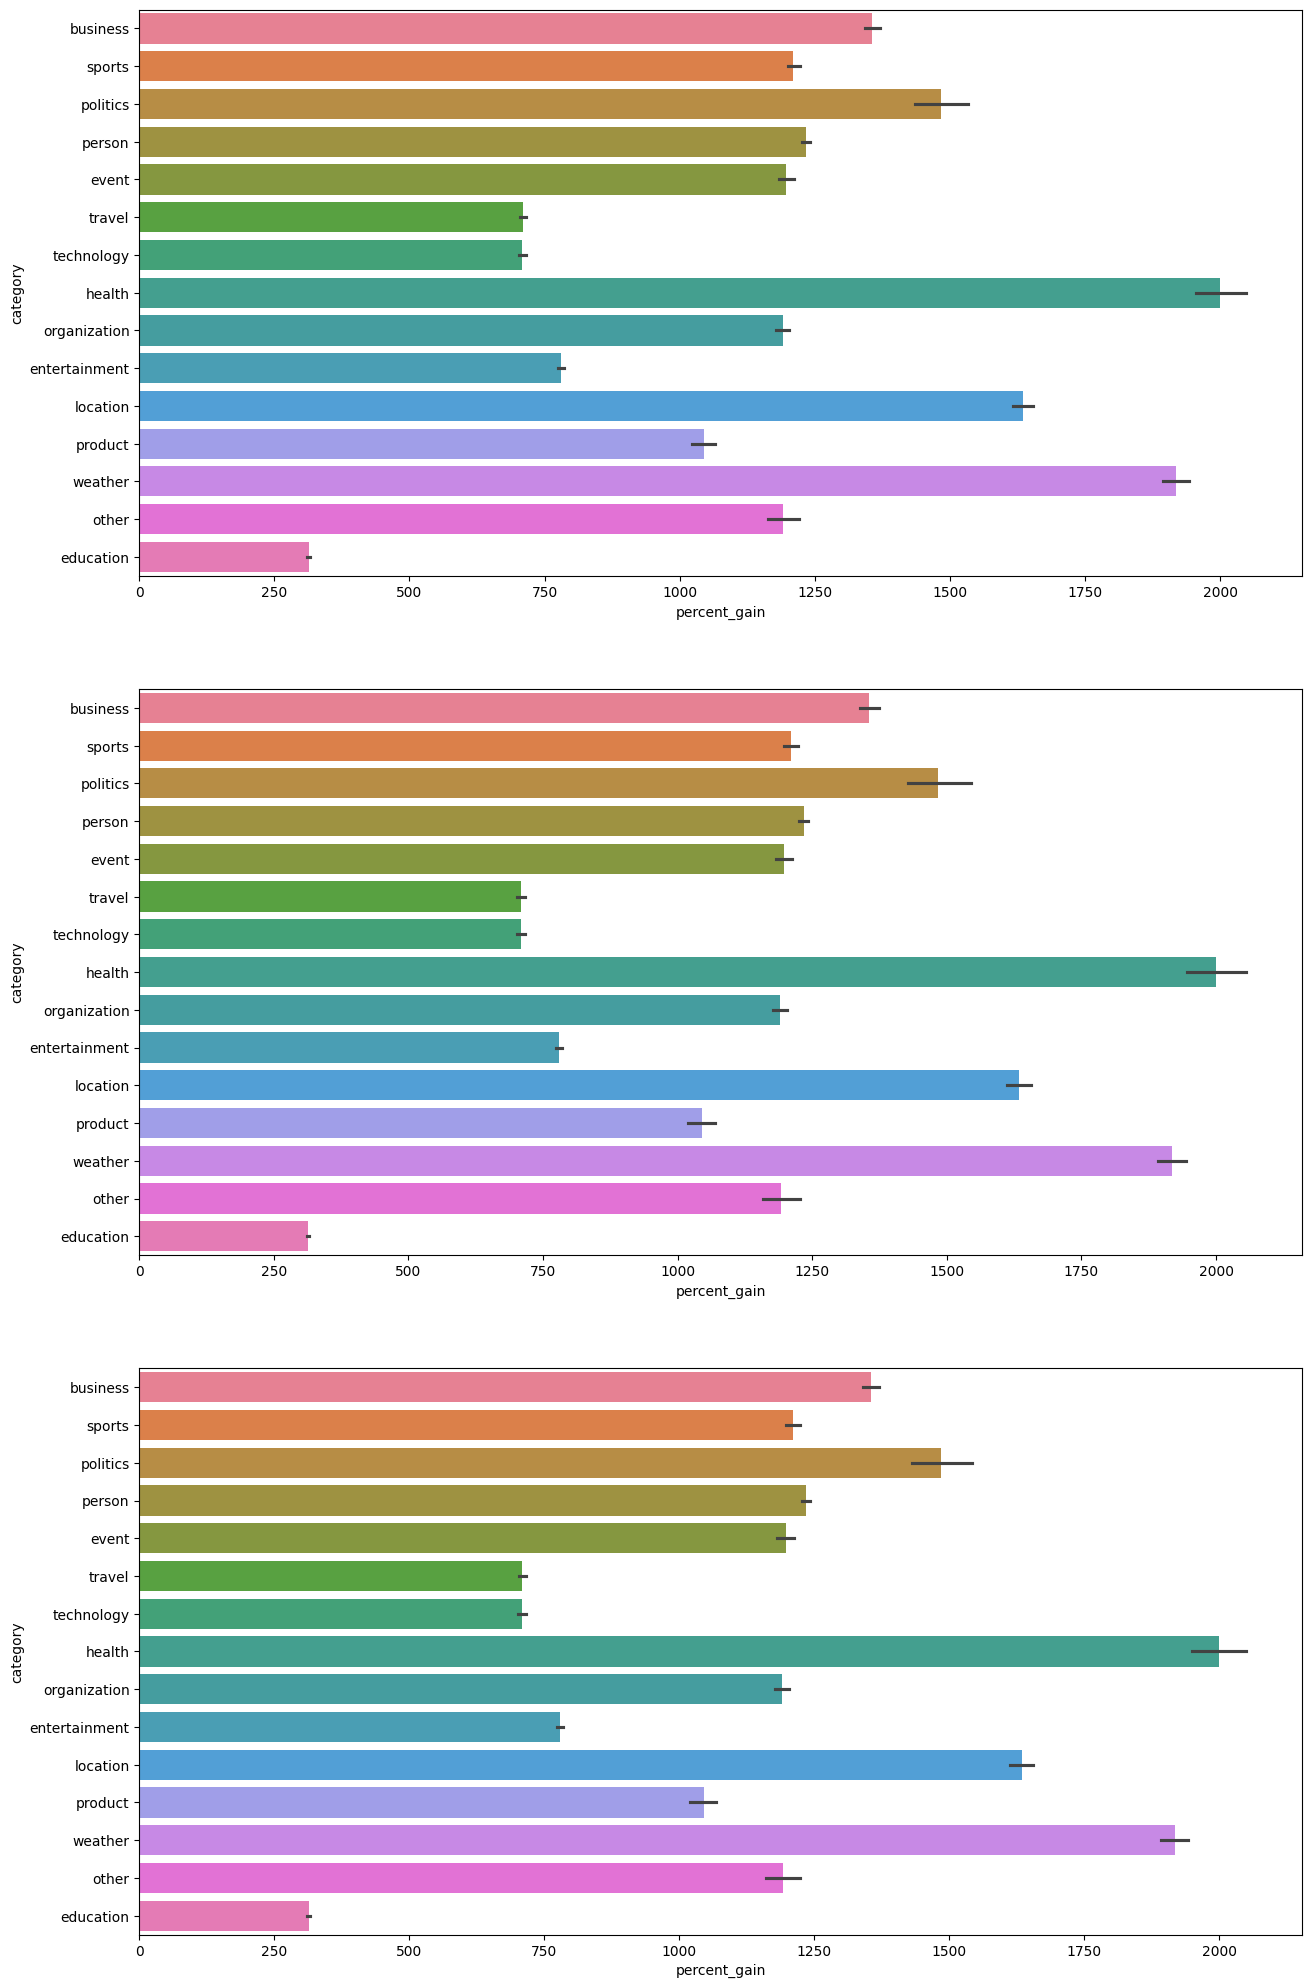

In [90]:
fig,ax=plt.subplots(nrows=3,ncols=1,figsize=(15,25))
ax1=ax[0];ax2=ax[1];ax3=ax[2];

sns.barplot(data=df_california,y='category',x='percent_gain',hue='category',ax=ax1)
sns.barplot(data=df_florida,y='category',x='percent_gain',hue='category',ax=ax2)
sns.barplot(data=df_ny,y='category',x='percent_gain',hue='category',ax=ax3);

# **CONCLUSION**
The analysis showed that, for the week studied, the dataset contains no regional variation; therefore, it is not possible to compare states or attribute behavioral differences to specific populations. The project’s most valuable finding is methodological: validating the data structure before interpreting the results prevented false conclusions. Nevertheless, the dataset made it possible to characterize dominant themes, temporal dynamics, and the persistence of terms.

Next steps: repeat the verification process for other weeks and tables within the dataset to determine whether the absence of regional variation is a general pattern, and filter out persistent terms suspected of being noise.

# **INISGHTS**
1. The data does not distinguish by region. Trends are identical across all 31 DMAs. Counts by state (California > New York > Florida) merely reflect the number of DMAs in each state (12, 10, and 9, respectively), rather than indicating higher search interest.
2. Dominant categories: "Sports" leads, followed by "People," "Entertainment," "Organizations," "Locations," "Technology," and "Business." In terms of growth (*percent_gain*), "Weather," "Locations," and "Business" stand out.
3. Persistent terms: *hebeos.com*, *zimbio.com*, and *Woodlands Inn* appear throughout the week, with their *percent_gain* increasing on weekends. Their constant presence suggests they may be "noise" or artifacts within the dataset rather than genuine trends.
4. Bilingual presence: English terms predominate, but there is a notable presence of Spanish terms (for example, *tiempo de mañana* appears with the same frequency as its English equivalent, *weather tomorrow*).
5. Temporal pattern: The dataset records only four snapshots per day (at 00:00, 06:00, 12:00, and 18:00), with the highest activity occurring at 18:00. By day of the week, Thursday has the highest count, though the differences between days are minimal.
6. Educational pattern: Terms such as *blooket join*, *gimkit*, *wayground*, *unblocked games*, and *ixl* suggest usage associated with educational platforms.